# ARC: three-run checkpoint evaluation

Compare all completed checkpoints copied on 29 October 2026 from `gp8l0xmb`, `9q76bfi4` and `fh6igknc`. Each checkpoint uses the same 64 evaluation track seeds and sampled policy, with 50,000 rliable percentile-bootstrap resamples for the IQM 95% interval.

The intervals describe evaluation episodes for a fixed checkpoint. Re-running this notebook loads saved scores and does not rerun environments. Collapsed checkpoints are retained. The snapshot manifest records exactly which checkpoints and artifacts were copied while the ARC jobs continued training.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "pyproject.toml").is_file()
    and (parent / "notebooks/plot_generation").is_dir()
)


## Settings

Choose `env_steps` for training environment interactions or `train_step` for gradient updates. Both are displayed in thousands. Adjust the report path, styles, axes and export filename here.


In [2]:
report_path = repo_root / "experiments/dreamer/evaluations/arc-three-runs-20261029/all-checkpoints.json"
export_stem = repo_root / "assets/arc-three-runs-iqm"
run_order = ["gp8l0xmb", "9q76bfi4", "fh6igknc"]
x_key = "env_steps"  # Or "train_step".
line_styles = ["-", "--", ":"]
figure_size = (9.5, 4.4)
y_limits = (-110, 1000)
x_tick_spacing = 100  # Thousands.
ci_alpha = 0.10
blk = "#343633"
off_white = "#F7F4EB"

plt.rcParams.update({
    "font.family": "Routed Gothic", "font.style": "normal", "font.size": 11,
    "figure.facecolor": off_white, "axes.facecolor": off_white, "figure.dpi": 120,
    "text.color": blk, "axes.labelcolor": blk, "axes.edgecolor": blk,
    "xtick.color": blk, "ytick.color": blk, "svg.fonttype": "none",
})


## Load the saved evaluations

The table below shows the latest checkpoint and the checkpoint with the largest observed IQM for each run. Selecting the largest observed score is descriptive; it does not establish a statistically best checkpoint.


In [3]:
report = json.loads(report_path.read_text())
assert report["num_episodes"] == 64
assert np.isclose(report["confidence_level"], 0.95)
groups = {run: sorted(
    [row for row in report["results"] if Path(row["checkpoint"]).parent.name == run],
    key=lambda row: row["train_step"],
) for run in run_order}

print(f"Completed checkpoints: {len(report['results'])}/{report['expected_checkpoints']}")
print(f"Episodes per checkpoint: {report['num_episodes']}")
for run_id, rows in groups.items():
    assert rows, f"No completed evaluation yet for {run_id}"
    assert all(len(row["returns"]) == 64 for row in rows)
    latest = rows[-1]
    peak = max(rows, key=lambda row: row["iqm"])
    low, high = latest["iqm_ci_95"]
    print(f"\n{latest['name']} ({run_id}), {len(rows)} checkpoints")
    print(f"  Latest: {latest['train_step']:,} updates; {latest['checkpoint_metadata']['env_steps']:,} environment steps")
    print(f"  Mean {latest['mean']:.2f}; median {latest['median']:.2f}; IQM {latest['iqm']:.2f} [{low:.2f}, {high:.2f}]")
    print(f"  Highest observed IQM: {peak['iqm']:.2f} at {peak['train_step']:,} updates")


Completed checkpoints: 58/58
Episodes per checkpoint: 64

arc-9202028-long (gp8l0xmb), 10 checkpoints
  Latest: 82,000 updates; 328,000 environment steps
  Mean 861.16; median 888.08; IQM 885.48 [879.70, 891.28]
  Highest observed IQM: 885.48 at 82,000 updates

arc-9203963-long (9q76bfi4), 21 checkpoints
  Latest: 153,600 updates; 768,000 environment steps
  Mean 360.76; median 363.10; IQM 363.67 [345.30, 382.42]
  Highest observed IQM: 864.07 at 89,600 updates

arc-9203250-long (fh6igknc), 27 checkpoints
  Latest: 252,000 updates; 1,008,000 environment steps
  Mean 850.15; median 853.51; IQM 854.75 [849.29, 862.06]
  Highest observed IQM: 909.97 at 202,000 updates


## IQM and 95% confidence intervals

Markers identify evaluated checkpoints; connecting lines are visual guides. Shading shows pointwise 95% episode-bootstrap intervals. The ink and paper palette and Routed Gothic font match the other ARC plots.


PNG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-three-runs-iqm.png
SVG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-three-runs-iqm.svg


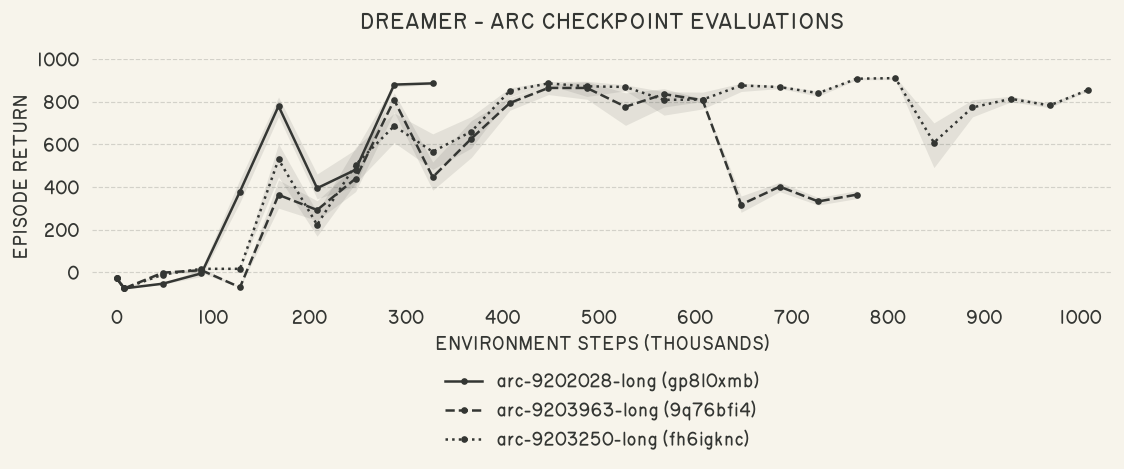

In [4]:
fig, ax = plt.subplots(figsize=figure_size)
for run_id, linestyle in zip(run_order, line_styles, strict=True):
    rows = groups[run_id]
    x = np.asarray([row["checkpoint_metadata"]["env_steps"] if x_key == "env_steps" else row["train_step"] for row in rows]) / 1000
    values = np.asarray([row["iqm"] for row in rows])
    bounds = np.asarray([row["iqm_ci_95"] for row in rows])
    assert np.isfinite(np.column_stack([x, values, bounds])).all()
    ax.fill_between(x, bounds[:, 0], bounds[:, 1], color=blk, alpha=ci_alpha, linewidth=0)
    ax.plot(x, values, color=blk, linestyle=linestyle, marker="o", markersize=3,
            linewidth=1.5, label=f"{rows[-1]['name']} ({run_id})")

ax.set_title("DREAMER - ARC CHECKPOINT EVALUATIONS", pad=18)
ax.set_xlabel("ENVIRONMENT STEPS (THOUSANDS)" if x_key == "env_steps" else "TRAINING UPDATES (THOUSANDS)")
ax.set_ylabel("EPISODE RETURN")
ax.set_ylim(*y_limits)
ax.margins(x=0.025)
ax.xaxis.set_major_locator(MultipleLocator(x_tick_spacing))
ax.yaxis.set_major_locator(MultipleLocator(200))
ax.set_axisbelow(True)
ax.grid(axis="y", color=blk, alpha=0.18, linestyle="--", linewidth=0.7)
ax.spines[:].set_visible(False)
ax.tick_params(axis="both", length=0, pad=8)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=1)
plt.tight_layout()
export_stem.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(export_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(export_stem.with_suffix(".svg"), bbox_inches="tight")
plt.show()
print(f"PNG: {export_stem.with_suffix('.png')}")
print(f"SVG: {export_stem.with_suffix('.svg')}")
